### Effect of a structured microbiome on the optimal immune repertoire

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib import patheffects
import scipy.optimize
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from math import erf
import multiprocessing as mp
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import random
import pandas as pd
import time
import plotly.graph_objects as go

sm = cm.ScalarMappable(norm = mcolors.Normalize(vmin=0.0, vmax=1.0), 
                           cmap=mpl.colormaps.get_cmap('Blues'))
cmap = plt.get_cmap('tab20c')
plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [3]:
# Define parameters
m, k = 20, 80 # (num_microbes, num_receptors)
n = np.ones(1) # Niche supply
h = np.ones(1) # harm per microbe of microbe
Sigma = np.ones(1)
beta = 0.1
tol=1e-10
# day0_abundance_data = pd.read_csv('./data/wang_tableS2.csv')
# hCom1 = day0_abundance_data.day0_abundance[~np.isnan(day0_abundance_data.day0_abundance)]/100

In [4]:
# Define functions
def G(l, sigma = 1, n = n): # Microbe steady state population
    out = n/(1 + np.sum(l*sigma))
    return out

def objective(l, beta = 1.0, Sigma = np.eye(m), h = np.ones(m), n = np.ones(m),  b = np.ones(m)): # Cost function
    # beta := Cost of immune pressure

    out = np.sum([h[i]*G(l, sigma, n[i]) for i, sigma in enumerate(Sigma)]) + np.sum(beta*l) + np.sum(Sigma.dot(l)*np.array([b[i]*G(l, sigma, n[i]) for i, sigma in enumerate(Sigma)]))

    return out.item()

# Define analytic solution
def single_receptor(beta, sigma = 1, h = 1.0, n = 1.0):
    if sigma/beta < n*h:
        out = 1/np.sqrt(sigma)*(np.sqrt(n*h/beta) - 1/np.sqrt(sigma))
    else:
        out = 0.0

    return out

## Simplest case: one microbe, one receptor

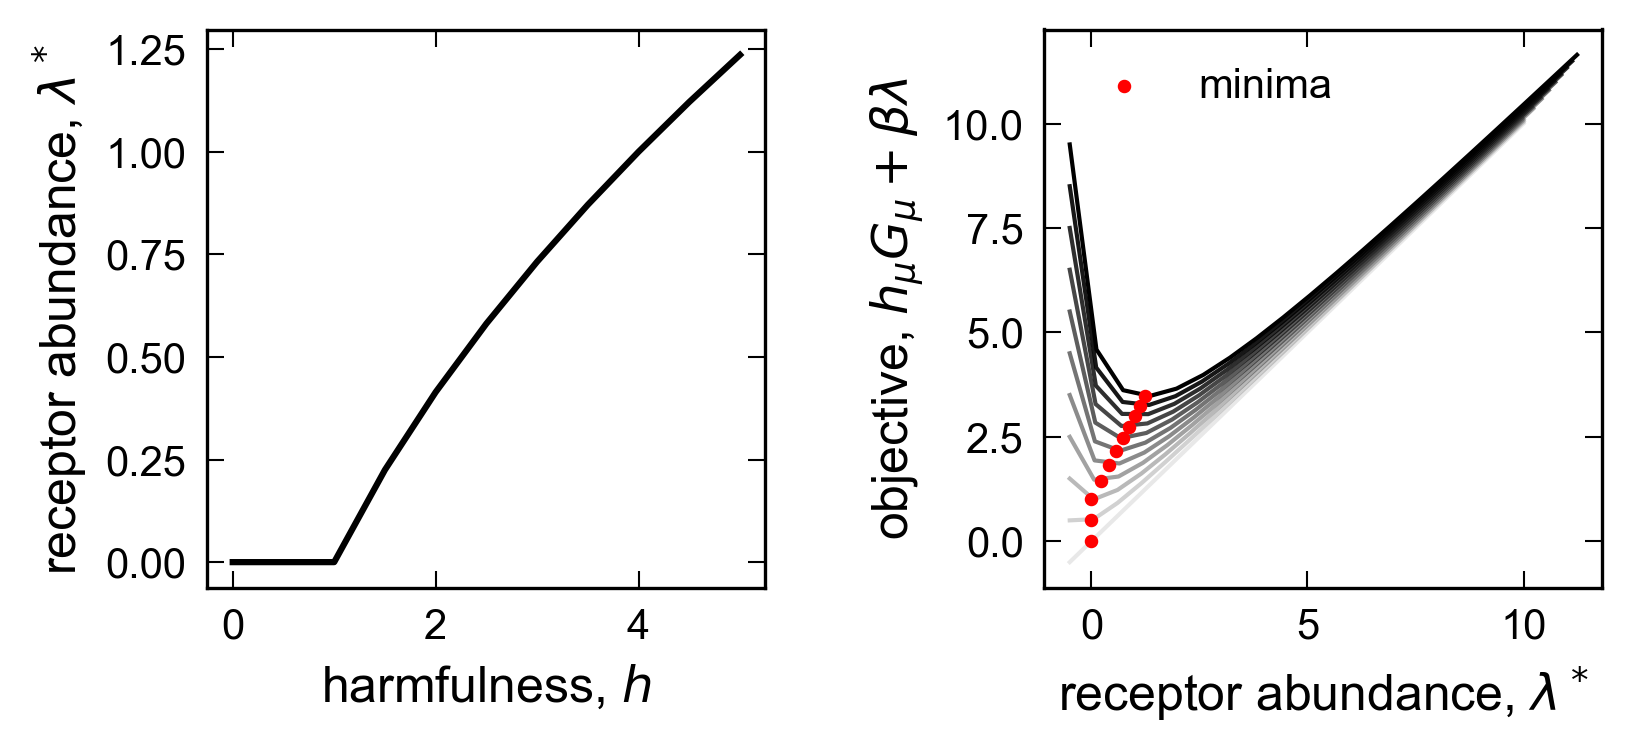

In [8]:
# Plot numerical values and analytic values verus beta
fig, (ax1, ax2) = plt.subplots(1, 2, dpi = 150, figsize=(6, 3))

hs = np.linspace(0, 5, 11)
for i, p in enumerate(hs):

    res = minimize(objective, args = (1.0, np.array(Sigma), np.array([p]), n, np.zeros(1)),
                 x0 = [0.1],
                 tol=tol,
                 constraints = LinearConstraint([1.0], 0.0, np.inf))

    # ax1.scatter(p, res.x, c= 'black', label = "numeric" if i == 0 else '')
    ls = np.linspace(-0.5, res.x + 10, 20)

    ax2.plot(ls, np.array([objective(j, 1.0, Sigma, np.array([p]), n, np.zeros(1)) for j in ls]), 'k', alpha = (i + 1)/len(hs))
    ax2.scatter(res.x, res.fun, color = 'red', s = 5, zorder = 2, label = "minima" if i == 0 else '')

ax1.plot(hs, np.array([single_receptor(n=j, beta = 1.0) for j in hs]), linewidth = 1.5, color = 'black',label = "analytic")
#ax1.title.set_text(r'one microbe, one receptor')

ax1.set(ylabel=r'receptor abundance, $\lambda^*$',xlabel=r'harmfulness, $h$')
ax1.minorticks_off()
# ax1.legend()
ax1.set_box_aspect(1)
ax2.set(xlabel=r'receptor abundance, $\lambda^*$',ylabel=r'objective, $h_\mu G_\mu + \beta \lambda$')
ax2.legend()
ax2.minorticks_off()
ax2.set_box_aspect(1)
fig.subplots_adjust(wspace=0.50, hspace=0.0)

fig.savefig('_figs/fig1_one_microbe_one_receptor'+'.pdf', dpi=300, bbox_inches='tight')

In [74]:
# # make things more complicated and add multiple microbes but with a single receptor
# fig, (ax1, ax2) = plt.subplots(1, 2, dpi = 150, figsize=(8, 3))

# betas = n*h*np.logspace(-2, 0, 20)
# m, k = 5, 1
# sigma_narrow = np.random.uniform(low=0.0, high=1.0, size=m)
# for i, p in enumerate(betas):

#     res = minimize(objective, args = (p, sigma_narrow, np.ones(m), np.ones(m), np.zeros(m)),
#                  x0 = [0.1],
#                  tol=tol,
#                  constraints = LinearConstraint([1.0], 0.0, np.inf))

#     ax1.scatter(p, res.x, c= 'black', label = "numeric" if i == 0 else '')
#     ls = np.linspace(-0.5, res.x + 1, 20)

#     ax2.plot(ls, np.array([objective(j, p, sigma_narrow, np.ones(m), np.ones(m), np.zeros(m)) for j in ls]), 'k', alpha = (i + 1)/len(betas))
#     ax2.scatter(res.x, res.fun, color = 'red', s = 5, zorder = 2, label = "minima" if i == 0 else '')

# ax1.plot(betas, np.array([single_receptor(j) for j in betas]), label = "analytic")
# ax1.title.set_text(r'many microbes, one receptor')

# ax1.set(ylabel=r'receptor abundance, $\lambda$',xlabel=r'cost of immunity, $\beta$')
# ax1.minorticks_off()
# ax1.legend()
# ax2.set(xlabel=r'receptor abundance, $\lambda$',ylabel=r'objective, $h_\mu G_\mu + \beta \lambda$')
# ax2.legend()
# ax2.minorticks_off()
# fig.subplots_adjust(wspace=0.50, hspace=0.0)

# fig.savefig('_figs/figSI1_many_microbe_one_receptor'+'.png', dpi=300, bbox_inches='tight')

## More complex case: two microbes, two receptors

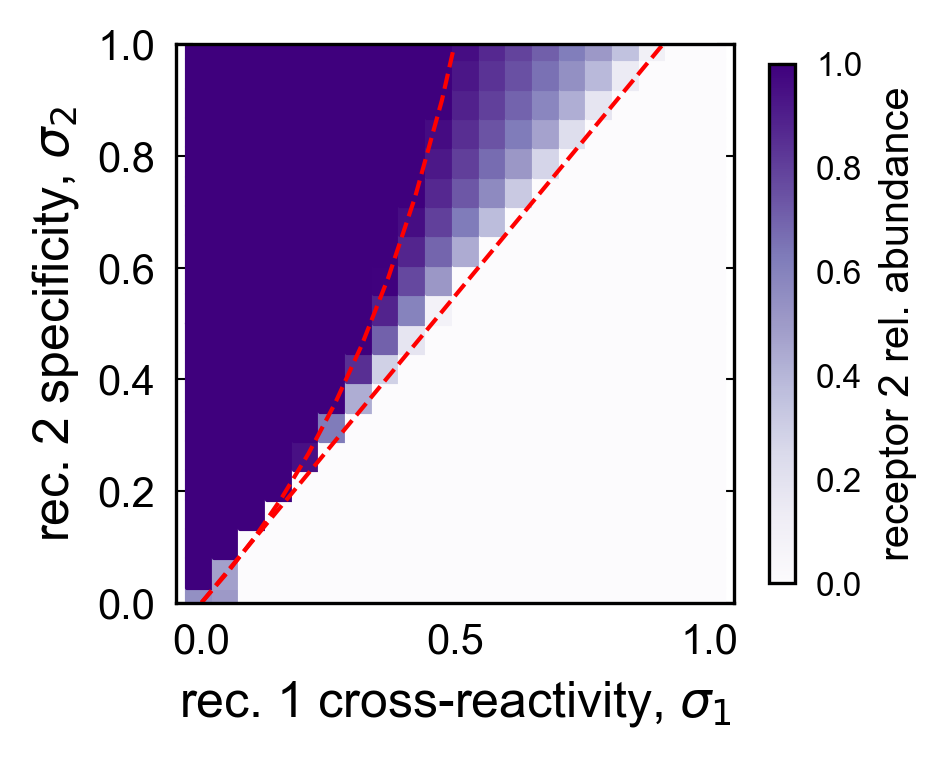

In [76]:
# Study impact of increasing receptor cross-reactivity
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
avg_Sigmas = []
h1,h2 = 1.0, 0.1
sigmas = np.linspace(0,1, 20)
cross_sigmas = np.array(np.meshgrid(sigmas, sigmas)).T.reshape(-1,2)

for cs in cross_sigmas:

    Sigma = np.array([[cs[0], cs[1]],[cs[0], 0.0]])

    # Minimize harm
    res_harm = minimize(objective, args = (beta, Sigma, [h1, h2], np.ones(2), np.zeros(2)),
             x0 = np.ones(2).tolist(),
             tol=tol,
             constraints = LinearConstraint(np.eye(2), 0.0, np.inf))
        
    lam_opts.append(res_harm.x)
    obj_opts.append(res_harm.fun)
    rec_num_opts.append(np.sum(res_harm.x > tol))
    X_opts.append(Sigma.dot(res_harm.x))

# Show that conditions are satisfied
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 3))
size = 50

im1 = ax1.scatter(cross_sigmas[:,0], cross_sigmas[:,1],
                 c = np.vstack(lam_opts)[:,1] /(np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1]),
                 cmap = 'Purples', marker = 's', norm = mpl.colors.Normalize(vmin = 0, vmax = 1),
                 s = size)

ax1.plot(sigmas, sigmas*(n*h1 + n*h2)/(n*h1), '--', color = 'red')
ax1.plot(sigmas[sigmas < beta/(n*h2)], sigmas[sigmas < beta/(n*h2)]/(1 - n*h2*sigmas[sigmas < beta/(n*h2)]/beta), 
         '--', color = 'red')
# ax1.axhline(y = beta/(n*h1), color = 'red', linestyle = '--')

ax1.set_ylim(0,1)
# ax1.set_title(r'two harmful microbes', fontsize = 10)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label("receptor 2 rel. abundance", fontsize = 10)
cb1.ax.tick_params(labelsize=8)
ax1.set(xlabel=r'rec. 1 cross-reactivity, $\sigma_{1}$',ylabel=r'rec. 2 specificity, $\sigma_{2}$')
ax1.minorticks_off()
ax1.set_box_aspect(1)

fig.savefig('_figs/fig2_receptor-cross-2d'+'.pdf', dpi=300, bbox_inches='tight')

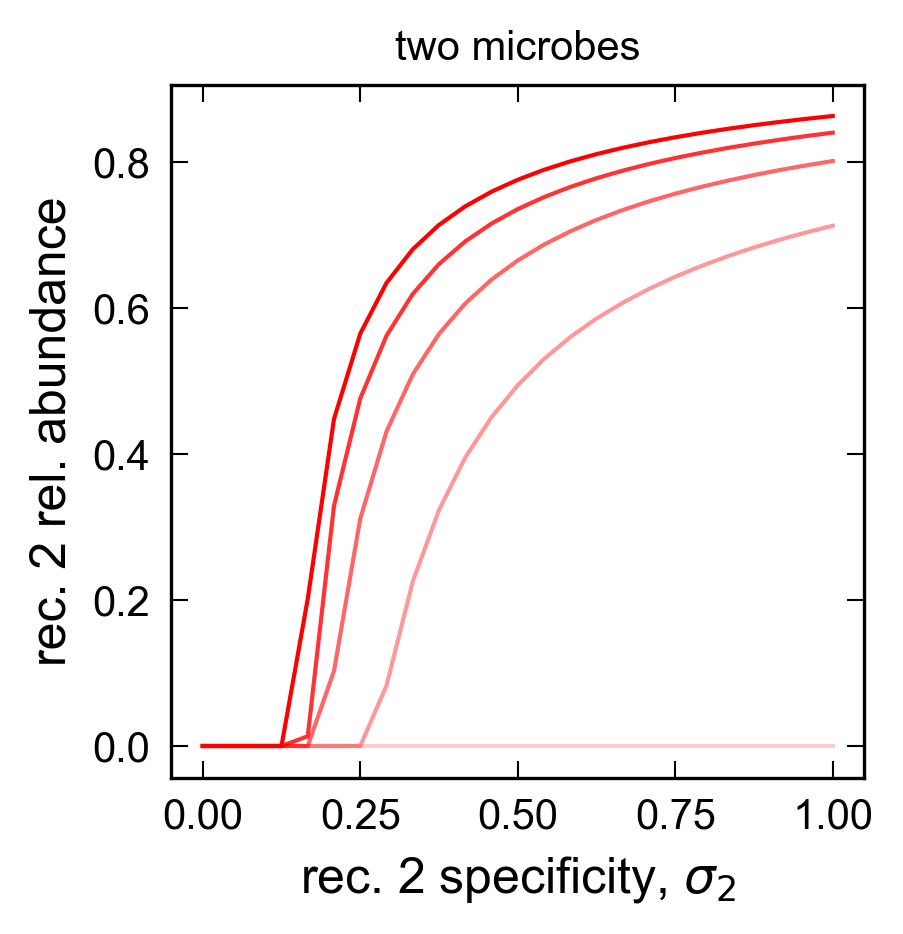

In [78]:
# Study impact of microbe harm per microbe on cross-reactivity results
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 3))
size = 50

sigmas = np.linspace(0,1, 25)
h2 = 1.0

for i, hs in enumerate(np.linspace(0.1,2,5)):
    lam_opts = []
    obj_opts = []
    rec_num_opts = []
    X_opts = []
    avg_Sigmas = []
    for cs in sigmas:
    
        Sigma = np.array([[0.1, cs],[0.1, 0.0]])
    
        # Minimize harm
        res_harm = minimize(objective, args = (beta, Sigma, [hs, h2], np.ones(2), np.zeros(2)),
                 x0 = np.ones(2).tolist(),
                 tol=1e-8,
                 constraints = LinearConstraint(np.eye(2), 0.0, np.inf))
            
        lam_opts.append(res_harm.x)
        obj_opts.append(res_harm.fun)
        rec_num_opts.append(np.sum(res_harm.x > 1e-8))
        X_opts.append(Sigma.dot(res_harm.x))
    
    ax1.plot(sigmas, np.vstack(lam_opts)[:,1] /(np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1]), color = 'red', alpha = (i + 1)/5) #label = r'$\frac{h_2}{h_1} =$'+str(hs))

ax1.set_title(r'two microbes', fontsize = 10)
ax1.set(xlabel=r'rec. 2 specificity, $\sigma_{2}$',ylabel=r'rec. 2 rel. abundance')
ax1.minorticks_off()
ax1.set_box_aspect(1)
fig.savefig('_figs/fig3_conserved-receptor-2d'+'.pdf', dpi=300, bbox_inches='tight')

## Moonshot case: One beneficial microbe, one harmful microbe, and two receptors.

In [8]:
Sigma = np.ones((2,3))
Sigma[1,0],Sigma[0,1] = 0.0, 0.0
Sigma

array([[1., 0., 1.],
       [0., 1., 1.]])

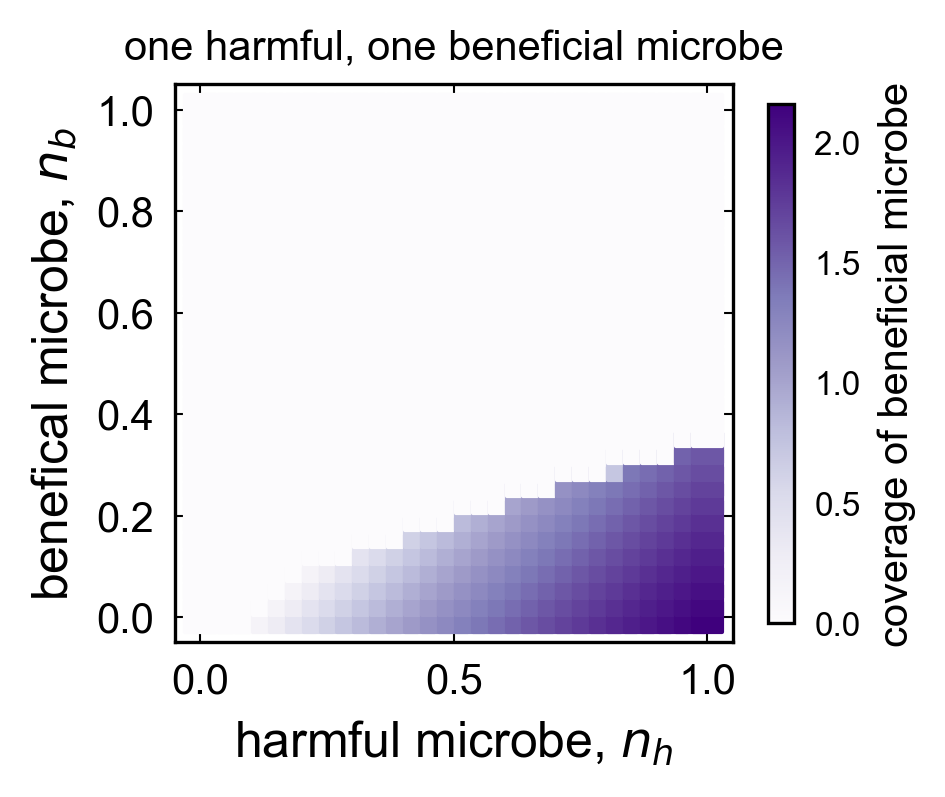

In [9]:
# Study impact of beneficial microbe on optimal repertoire
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
avg_Sigmas = []
vars = np.array(np.meshgrid(np.linspace(0,1, 31),np.linspace(0,1.0,31))).T.reshape(-1,2)

for [nh,nb] in vars:

    Sigma = np.ones((2,3))
    Sigma[0,0], Sigma[1,1] = 0.5, 0.5
    Sigma[1,0], Sigma[0,1] = 0.0, 0.0

    # Minimize harm
    res_harm = minimize(objective, args = (beta, Sigma, np.array([1.0, 0.0]), np.array([nh, nb]), np.array([0.0,1.0])),
             x0 = (1*np.ones(3)).tolist(),
             tol=tol,
             constraints = LinearConstraint(np.eye(3), 0.0, np.inf))
        
    lam_opts.append(res_harm.x)
    obj_opts.append(res_harm.fun)
    rec_num_opts.append(np.sum(res_harm.x > tol))
    X_opts.append(Sigma.dot(res_harm.x))

# Show that conditions are satisfied
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 3))
size = 50

im1 = ax1.scatter(vars[:,0], vars[:,1],
                 c = np.vstack(X_opts)[:,1],
                 cmap = 'Purples', marker = 's', norm = mpl.colors.Normalize(vmin = 0),
                 s = size)

#ax1.plot(np.linspace(0,1, 10), np.linspace(0,1, 10), 'k--')

ax1.set_title(r'one harmful, one beneficial microbe', fontsize = 10)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label("coverage of beneficial microbe", fontsize = 10)
cb1.ax.tick_params(labelsize=8)
ax1.set(ylabel=r'benefical microbe, $n_b$',xlabel=r'harmful microbe, $n_h$')
ax1.minorticks_off()
ax1.set_box_aspect(1)

fig.savefig('_figs/fig9_microbe-benefit-2d'+'.png', dpi=300, bbox_inches='tight')

Is there bistability in the region of high benefits? Looks like maybe it's just a region of numerical instability when both receptor populations tend to zero.

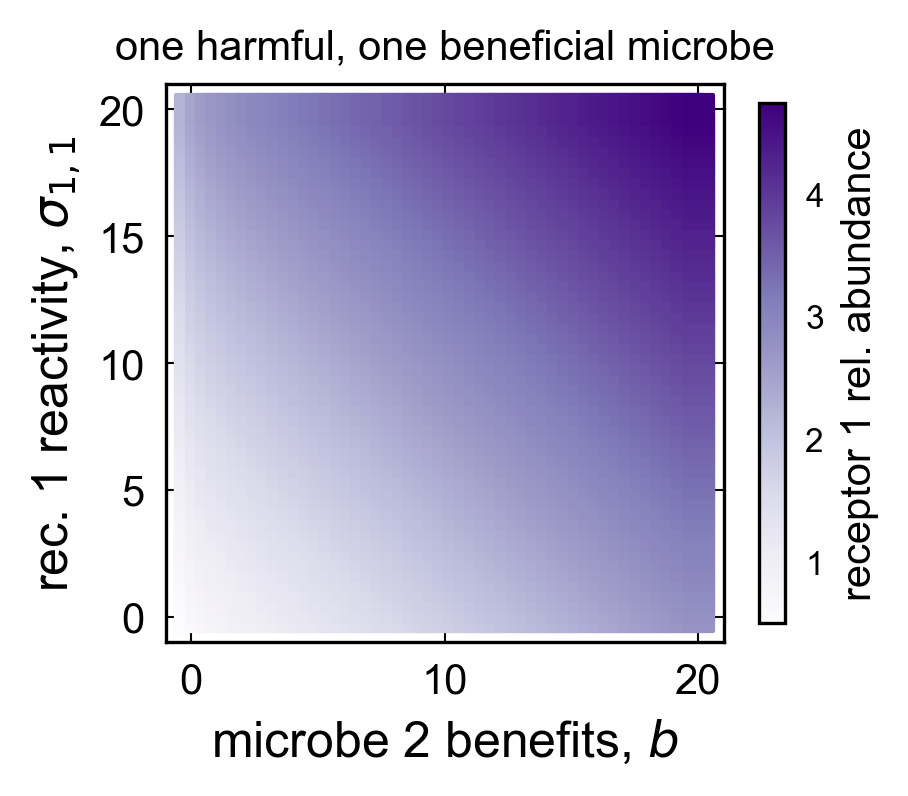

In [10]:
# Visualize cost landscape
pnts = 50
lvec = np.linspace(0.0, 20, pnts)

Sigma = np.ones((2,2))
Sigma[1,0], Sigma[0,0] = 0.0, 0.05
ls = np.array(list(itertools.product(lvec.tolist(),lvec.tolist())))
l1, l2 = np.meshgrid(lvec, lvec)
# z = np.array([objective(q, "two_m_two_r", 0.1*h/s, 
#                         np.vstack([np.array([3/4, 1/2]), np.array([1/2, 3/4])])) for q in ls]).reshape(pnts,pnts)
z = np.array([objective(q, beta, Sigma, np.array([1.0, 0.0]), np.ones(2)/2, np.array([0.0,1.5])) for q in ls]).reshape(pnts,pnts)

fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 3))
size = 50

im1 = ax1.scatter(l1, l2,
                 c = z,
                 cmap = 'Purples', marker = 's', norm = mpl.colors.Normalize(),
                 s = size)

ax1.set_title(r'one harmful, one beneficial microbe', fontsize = 10)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label("receptor 1 rel. abundance", fontsize = 10)
cb1.ax.tick_params(labelsize=8)
ax1.set(ylabel=r'rec. 1 reactivity, $\sigma_{1,1}$',xlabel=r'microbe 2 benefits, $b$')
ax1.minorticks_off()
ax1.set_box_aspect(1)

# fig = go.Figure(data=[go.Surface(z=z, x=l1, y=l2)])
# fig.update_traces(contours_z=dict(show=True, usecolormap=True,
#                                   highlightcolor="limegreen", project_z=True))
# fig.update_layout(title='Cost function - mixed', autosize=False,
#                   scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
#                   width=500, height=500,
#                   margin=dict(l=65, r=50, b=65, t=90))

# # Update the layout
# fig.update_layout(scene=dict(
#     xaxis_title=r'Receptor 1',
#     yaxis_title=r'Receptor 2',
#     zaxis_title=r'Objective'
# ))

# fig.show()

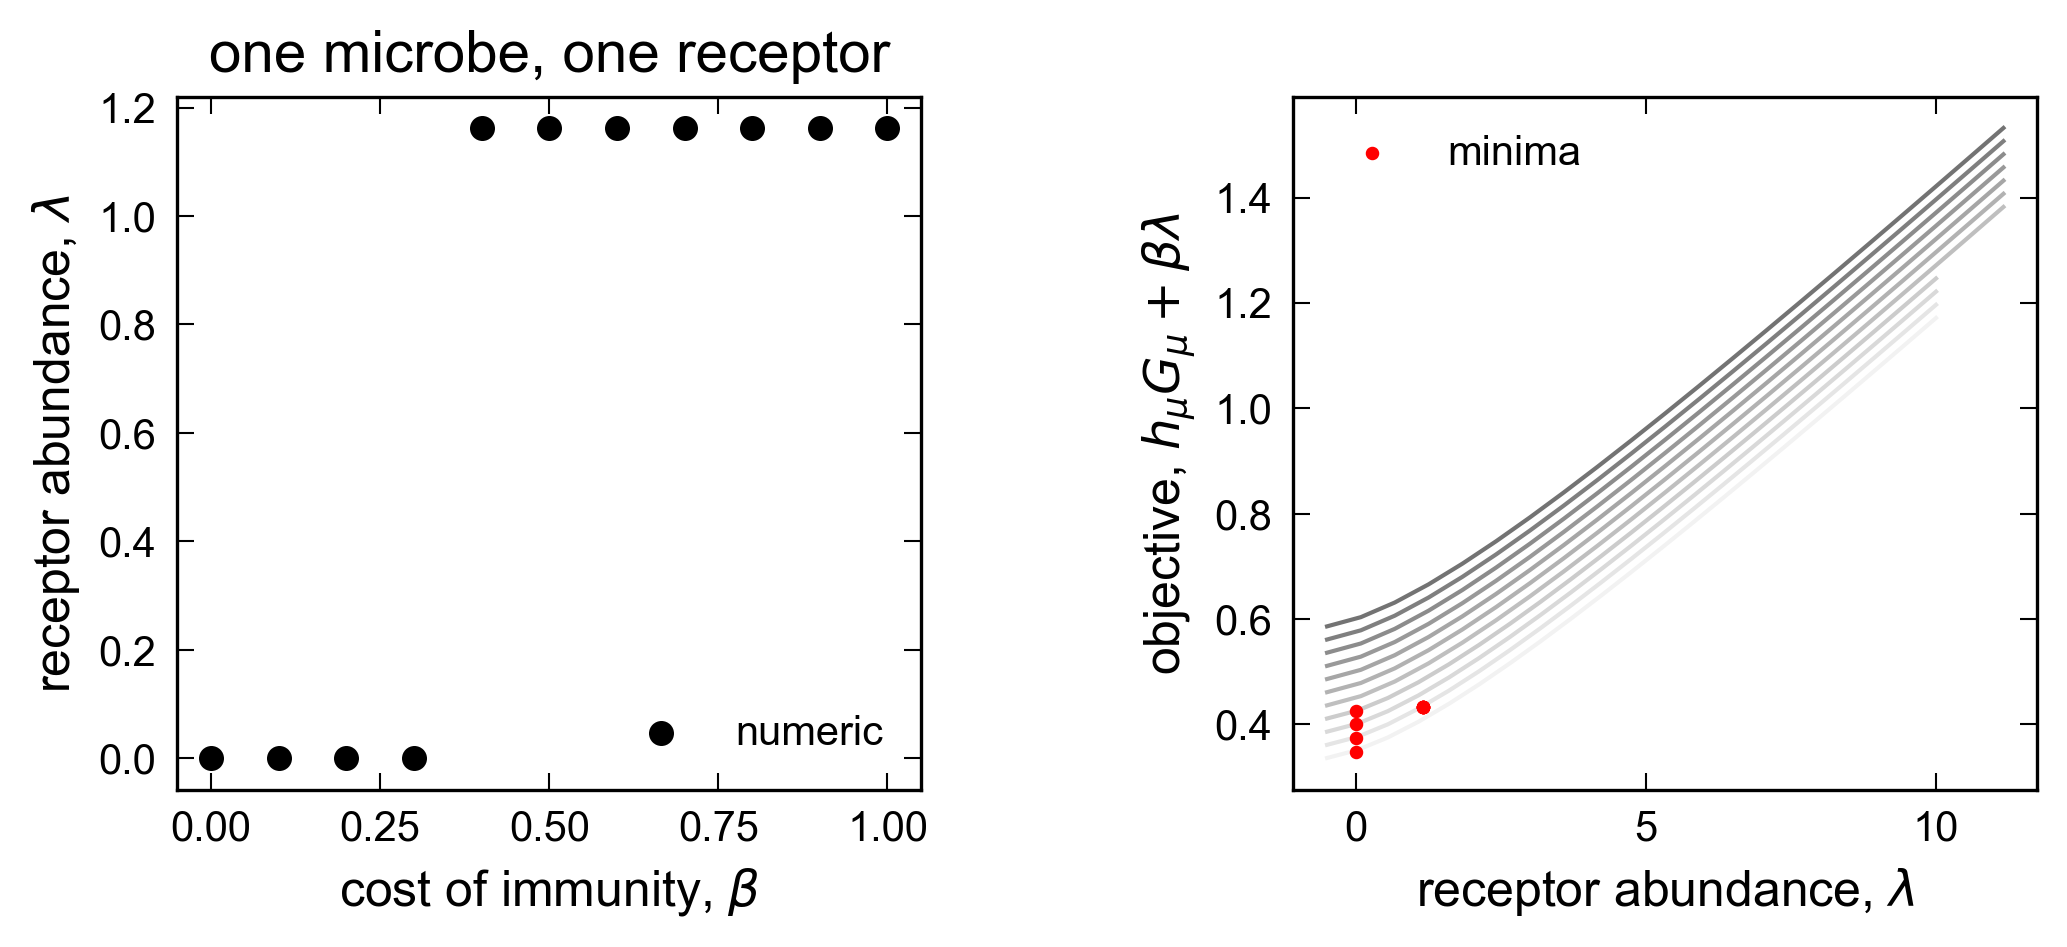

In [11]:
# Plot numerical values and analytic values verus beta
fig, (ax1, ax2) = plt.subplots(1, 2, dpi = 150, figsize=(8, 3))

bs = n*h*np.linspace(0, 1, 11)
Sigma = np.ones((2,2))
Sigma[1,0], Sigma[0,0] = 0.0, 0.5

for i, p in enumerate(bs):

    res = minimize(objective, args = (beta, np.array(Sigma), np.array([1.0, 0.0]), np.ones(2)/2, np.array([0.0,p])),
                 x0 = [1.0, 1.0],
                 tol=tol,
                 constraints = LinearConstraint(np.eye(2), 0.0, np.inf))

    ax1.scatter(p, res.x[0], c= 'black', label = "numeric" if i == 0 else '')
    ls = np.linspace(-0.5, res.x[0] + 10, 21)

    ax2.plot(ls, np.array([objective(np.array([j,1.0]), beta, Sigma, np.array([1.0, 0.0]), np.ones(2)/2, np.array([0.0,p])) for j in ls]), 'k', alpha = (i + 1)/len(betas))
    ax2.scatter(res.x[0], res.fun, color = 'red', s = 5, zorder = 2, label = "minima" if i == 0 else '')

ax1.title.set_text(r'one microbe, one receptor')

ax1.set(ylabel=r'receptor abundance, $\lambda$',xlabel=r'cost of immunity, $\beta$')
ax1.minorticks_off()
ax1.legend()
ax2.set(xlabel=r'receptor abundance, $\lambda$',ylabel=r'objective, $h_\mu G_\mu + \beta \lambda$')
ax2.legend()
ax2.minorticks_off()
fig.subplots_adjust(wspace=0.50, hspace=0.0)

#fig.savefig('_figs/fig1_one_microbe_one_receptor'+'.png', dpi=300, bbox_inches='tight')

### Unstructured microbe-receptor interactions
For a community of $M$ microbes, construct a repertoire of $j \leq M$ receptors which randomly bind to a subset of microbes by targeting a single conserved gene, i.e. $\sigma_{\mu,j} \sim \text{Bernoulli}(p)$. What should the optimal repertoire be? How does it change with cluster number?

In [12]:
# A potential problem: why doesn't this sum to 1
np.sum(hCom1.values)

0.93998154736281

In [53]:
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
obj_X_dist = []
obj_minimizer_dist = []
rec_cov_dist = []

m, k = len(hCom1), 100
pcr = 0.1
runs = 100
hs = 1/k*np.logspace(0, 2, 11)

for i, p in enumerate(hs):
    obj_min, obj_minimizer_cumul, obj_minimizer, obj_rec_num, X, obj_X_ratio, rec_cov = 0.0, 0.0, [], 0.0, 0.0, [], []
    for r in np.arange(0,runs):
        Sigma = np.unique(np.random.binomial(1, pcr, size = (m,k)).dot(np.diag(np.random.uniform(low=0.0, high=1.0, size=k))), axis = 1)
        res_harm = minimize(objective, args = (1/k, Sigma, p*np.ones(m), hCom1.values, np.zeros(m)),
                 x0 = np.ones(Sigma.shape[1]).tolist(),
                 tol=tol,
                 constraints = LinearConstraint(np.eye(Sigma.shape[1]), 0.0, np.inf))
        obj_min += res_harm.fun
        obj_minimizer_cumul += np.sum(res_harm.x)
        obj_minimizer += (res_harm.x).tolist()
        obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
        rec_cov += np.sum(np.diag(hCom1.values).dot(Sigma), axis = 0).tolist()
        obj_rec_num += np.sum(res_harm.x > tol)
        X += Sigma.dot(np.maximum(res_harm.x,0))
        
    lam_opts.append(obj_minimizer_cumul/runs)
    obj_opts.append(obj_min/runs)
    obj_minimizer_dist.append(obj_minimizer)
    obj_X_dist.append(obj_X_ratio)
    rec_cov_dist.append(rec_cov)
    rec_num_opts.append(obj_rec_num/runs)
    X_opts.append(X/runs)

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/2224875824.py:25: RuntimeWarning: invalid value encountered in divide
  obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/2224875824.py:25: RuntimeWarning: invalid value encountered in divide
  obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/2224875824.py:25: RuntimeWarning: invalid value encountered in divide
  obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/2224875824.py:25: RuntimeWarning: invalid value encountered in divide
  obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/2224875

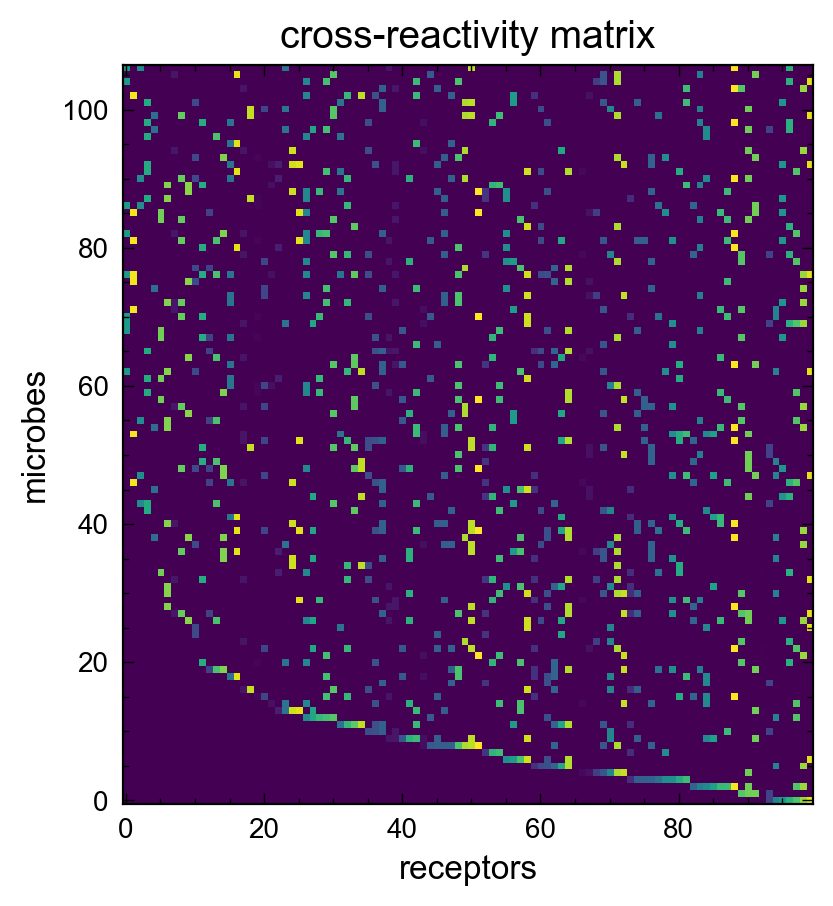

In [54]:
plt.imshow(Sigma, cmap='viridis', origin='lower') # 'viridis' is a common colormap
#plt.colorbar(label='Value') # Add a color bar to indicate value mapping
plt.title('cross-reactivity matrix')
plt.xlabel('receptors')
plt.ylabel('microbes')
plt.savefig('_figs/fig8_structured_receptor_matrix'+'.png', dpi=300, bbox_inches='tight')

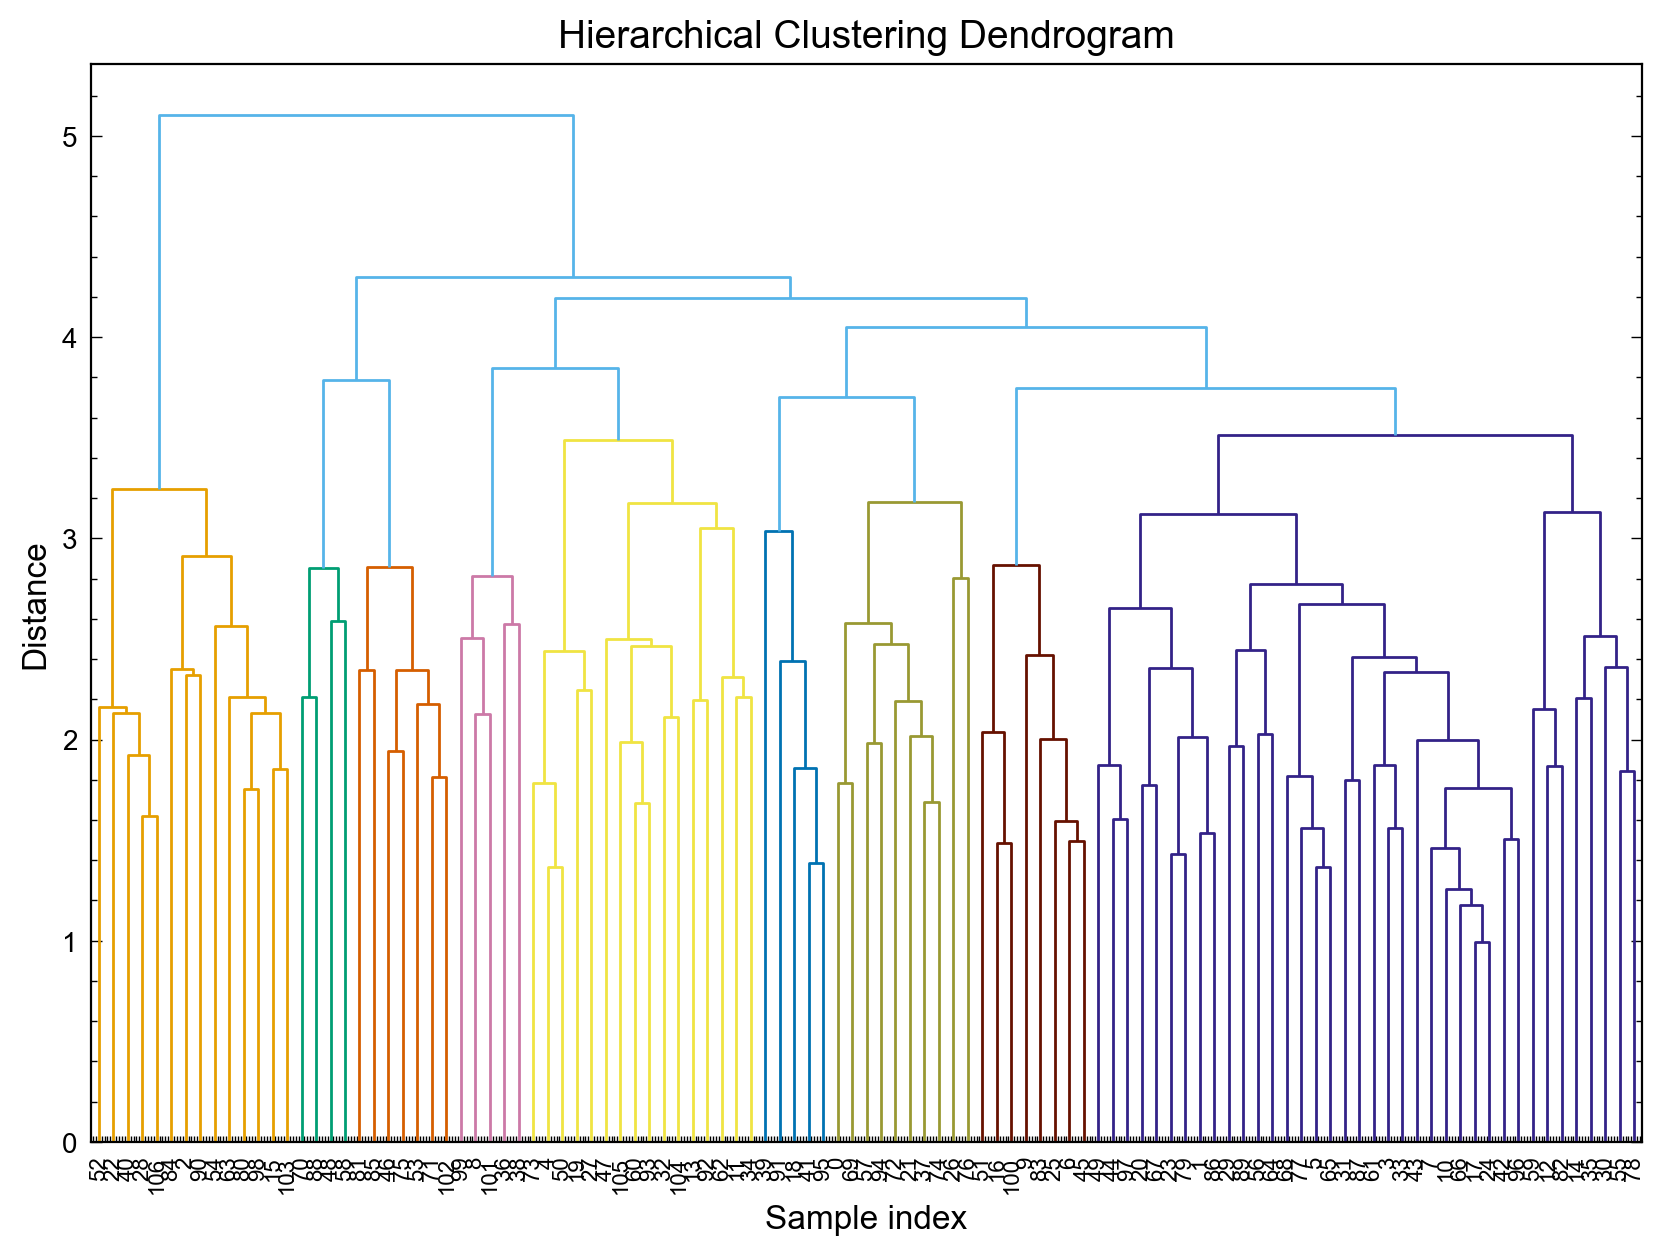

In [55]:
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import linkage
# Perform hierarchical clustering using 'ward' linkage method
Z = linkage(Sigma, 'ward')

plt.figure(figsize=(10, 7))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample index')
plt.ylabel('Distance')
dendrogram(
    Z,
    # labels=your_labels_list, # Optional: provide labels for your samples
    leaf_rotation=90.,  # Rotates the x-axis labels
    leaf_font_size=8.,  # Font size for the x-axis labels
)
plt.show()

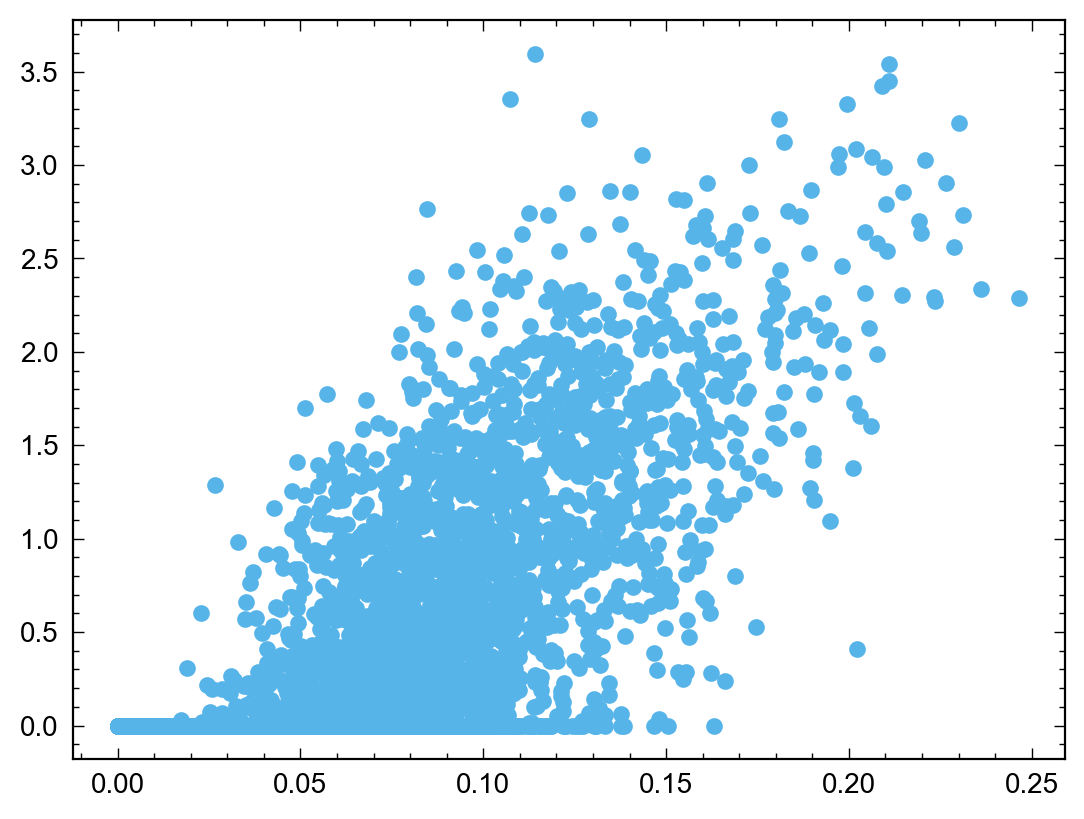

In [56]:
plt.scatter(rec_cov_dist[-1], obj_minimizer_dist[-1])

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/3536484908.py:8: RuntimeWarning: Mean of empty slice
  axs[3].scatter(hs[i], np.nanmean(np.array(rec_cov_dist[i])[(np.array(obj_minimizer_dist[i]) > tol)]/m), color = cmap(i))


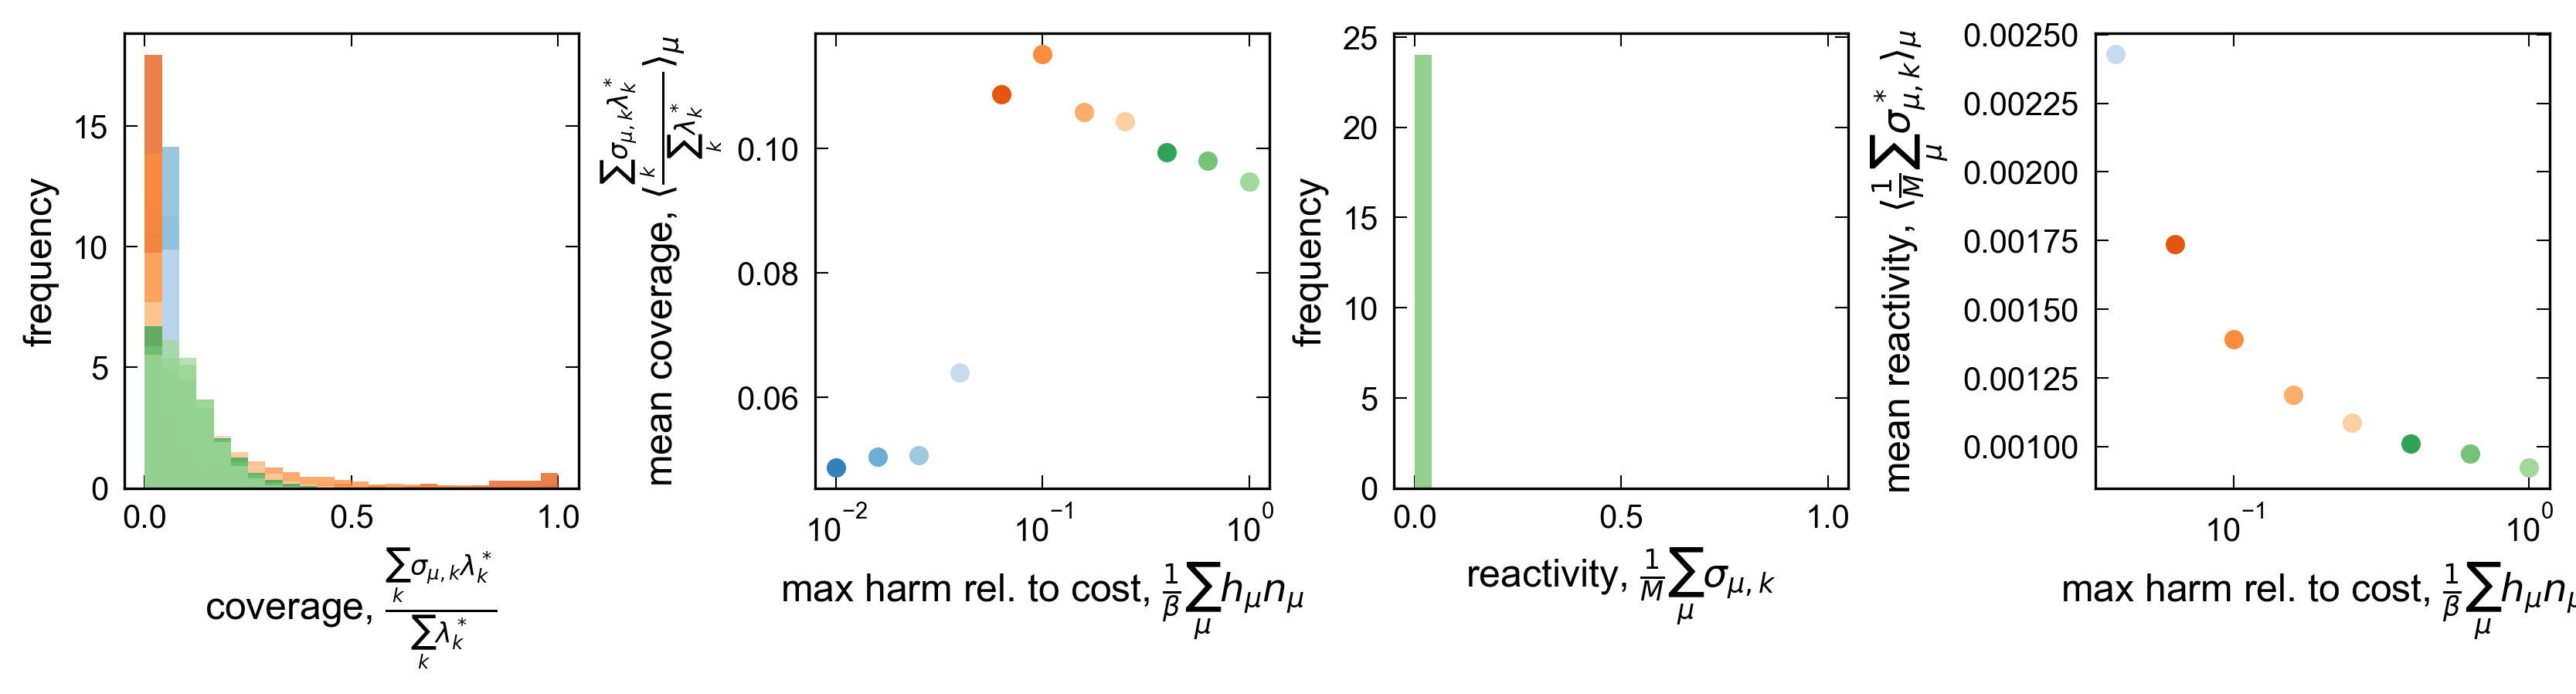

In [57]:
fig, axs = plt.subplots(1, 4, dpi = 150, figsize=(11, 3), constrained_layout = True)

for i,d in enumerate(obj_X_dist):
    axs[0].hist(np.maximum(d,tol), bins = np.linspace(0,1,25), density = True, alpha = 0.75, color = cmap(i), label = r'$\sum_\mu h_\mu n_\mu =$'+str(np.round(hs[i],3)));
    axs[1].scatter(hs[i], np.nanmean(np.maximum(d,tol)), color = cmap(i))
    axs[2].hist(np.array(rec_cov_dist[i])[(np.array(obj_minimizer_dist[i]) > tol)]/m, bins = np.linspace(0,1,25), density = True, color = cmap(i),
                alpha = 0.75, label = r'$\sum_\mu h_\mu n_\mu =$'+str(np.round(hs[i],3)));
    axs[3].scatter(hs[i], np.nanmean(np.array(rec_cov_dist[i])[(np.array(obj_minimizer_dist[i]) > tol)]/m), color = cmap(i))

axs[1].semilogx()
axs[3].semilogx()

axs[0].set(ylabel=r'frequency',xlabel=r'coverage, $\frac{\sum_k\sigma_{\mu,k}\lambda_k^*}{\sum_k\lambda_k^*}$')
axs[1].set(ylabel=r'mean coverage, $\langle \frac{\sum_k\sigma_{\mu,k}\lambda_k^*}{\sum_k\lambda_k^*}\rangle_\mu$',xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')
axs[2].set(ylabel=r'frequency',xlabel=r'reactivity, $\frac{1}{M}\sum_\mu\sigma_{\mu,k}$')
axs[3].set(ylabel=r'mean reactivity, $\langle \frac{1}{M}\sum_\mu\sigma_{\mu,k}^*\rangle_\mu$',xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')

for j, ax in enumerate(axs.flat):
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.yaxis.set_tick_params(labelleft=True)
    ax.minorticks_off()
    ax.set_box_aspect(1)

fig.savefig('_figs/fig6_coverage_structured_receptor_binding'+'.png', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_98734/3811090437.py:15: RuntimeWarning: divide by zero encountered in divide
  axs[3].scatter(hs, [np.sum(u/(lam_opts[i] if lam_opts[i] > tol else 0))/m for i,u in enumerate(X_opts)], color = [cmap(i) for i, c in enumerate(hs)])


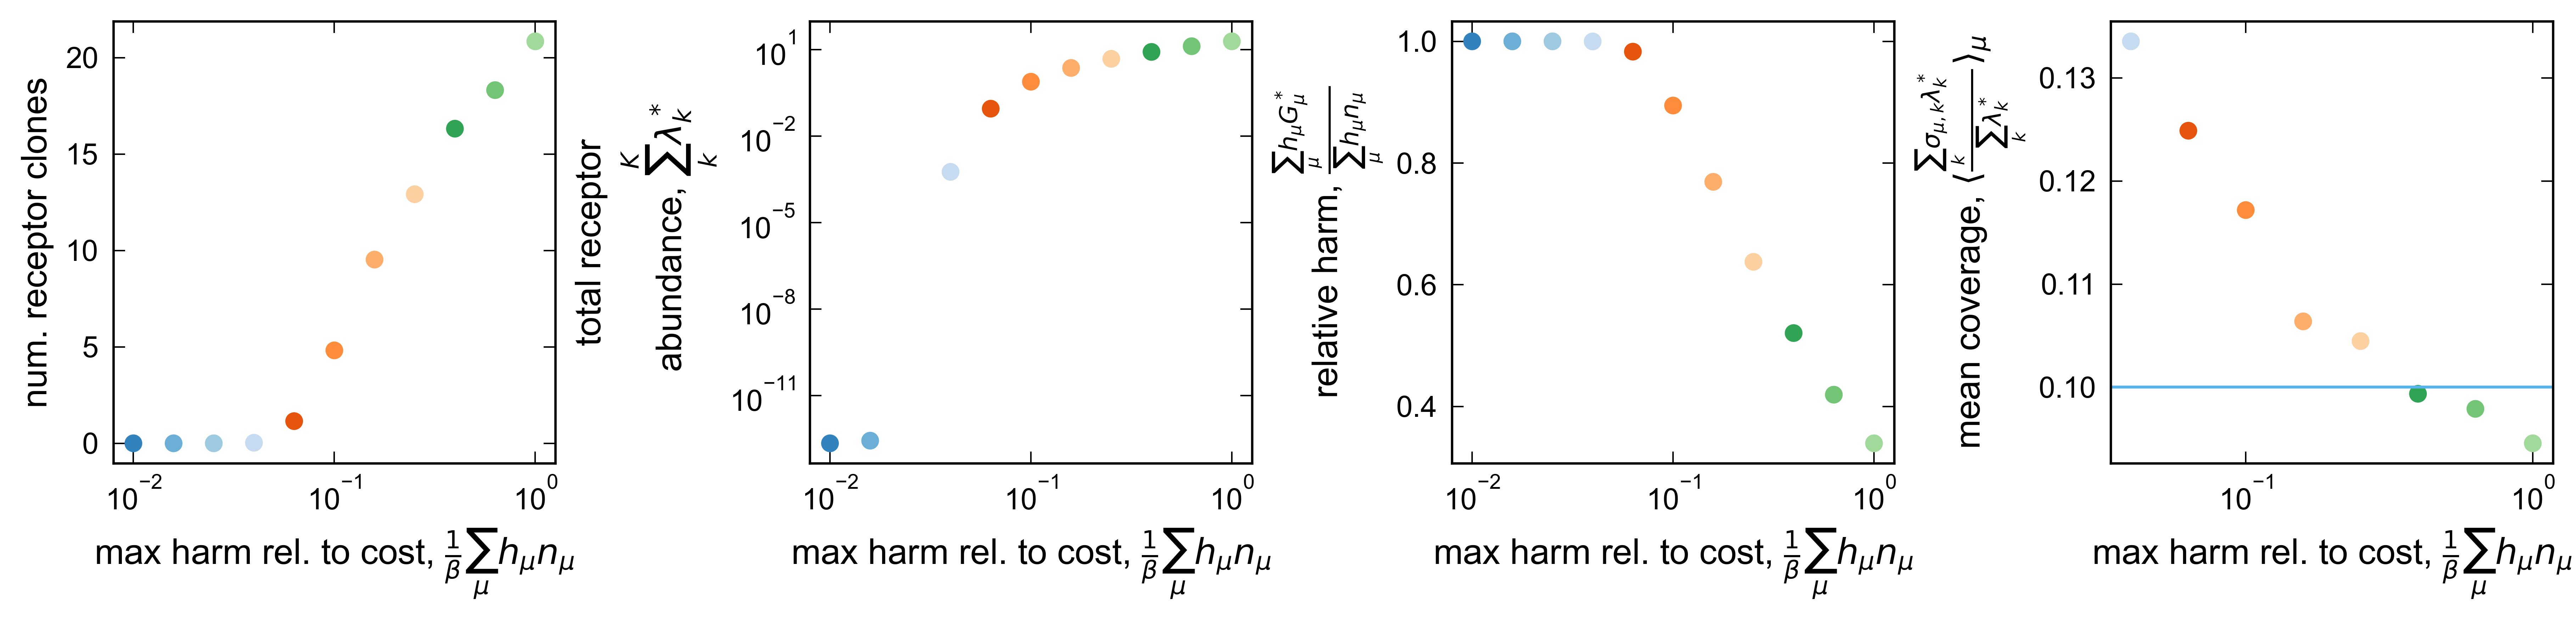

In [58]:
# Plot numerical values and analytic values verus beta
fig, axs = plt.subplots(1, 4, dpi = 300, figsize=(12, 3), layout='constrained')

axs[0].scatter(hs, rec_num_opts, color = [cmap(i) for i, c in enumerate(hs)])
# axs[0].plot([1.0,m], [1.0,m], 'k--')
axs[0].set(ylabel=r'num. receptor clones',xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')

axs[1].scatter(hs, lam_opts, color = [cmap(i) for i, c in enumerate(hs)])
axs[1].set(ylabel='total receptor\n abundance, '+r'$\sum_k^K \lambda_k^*$', xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')
axs[1].semilogy()

axs[2].scatter(hs, (np.array(obj_opts) - 1/k*np.array(lam_opts))/np.array(hs*np.sum(hCom1)), color = [cmap(i) for i, c in enumerate(hs)])
axs[2].set(ylabel=r'relative harm, $\frac{\sum_\mu h_\mu G_\mu^*}{\sum_\mu h_\mu n_\mu}$', xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')

axs[3].scatter(hs, [np.sum(u/(lam_opts[i] if lam_opts[i] > tol else 0))/m for i,u in enumerate(X_opts)], color = [cmap(i) for i, c in enumerate(hs)])
axs[3].set(ylabel=r'mean coverage, $\langle \frac{\sum_k\sigma_{\mu,k}\lambda_k^*}{\sum_k\lambda_k^*}\rangle_\mu$', xlabel=r'max harm rel. to cost, $\frac{1}{\beta}\sum_\mu h_\mu n_\mu$')
axs[3].axhline(y = pcr)

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.yaxis.set_tick_params(labelleft=True)
    ax.minorticks_off()
    ax.set_box_aspect(1)

fig.savefig('_figs/fig7_many_receptors_binding_prob'+'.png', dpi=300, bbox_inches='tight')

#### Effect of cross-reactivity, $p$

In [50]:
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
obj_X_dist = []
obj_minimizer_dist = []
rec_cov_dist = []

m, k = len(hCom1), 100
runs = 25
ps = np.logspace(np.log10(1/m), np.log10(1/2), 11)

for i, p in enumerate(ps):
    obj_min, obj_minimizer_cumul, obj_minimizer, obj_rec_num, X, obj_X_ratio, rec_cov = 0.0, 0.0, [], 0.0, 0.0, [], []
    for r in np.arange(0,runs):
        Sigma = np.unique(np.random.binomial(1, p, size = (m,k)).dot(np.diag(np.random.uniform(low=0.0, high=1.0, size=k))), axis = 1)
        res_harm = minimize(objective, args = (1/k, Sigma, np.ones(m), hCom1.values, np.zeros(m)),
                 x0 = np.ones(Sigma.shape[1]).tolist(),
                 tol=tol,
                 constraints = LinearConstraint(np.eye(Sigma.shape[1]), 0.0, np.inf))
        obj_min += res_harm.fun
        obj_minimizer_cumul += np.sum(res_harm.x)
        obj_minimizer += (res_harm.x).tolist()
        obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
        rec_cov += np.sum(np.diag(hCom1.values).dot(Sigma), axis = 0).tolist()
        obj_rec_num += np.sum(res_harm.x > tol)
        X += Sigma.dot(np.maximum(res_harm.x,0))
        
    lam_opts.append(obj_minimizer_cumul/runs)
    obj_opts.append(obj_min/runs)
    obj_minimizer_dist.append(obj_minimizer)
    obj_X_dist.append(obj_X_ratio)
    rec_cov_dist.append(rec_cov)
    rec_num_opts.append(obj_rec_num/runs)
    X_opts.append(X/runs)

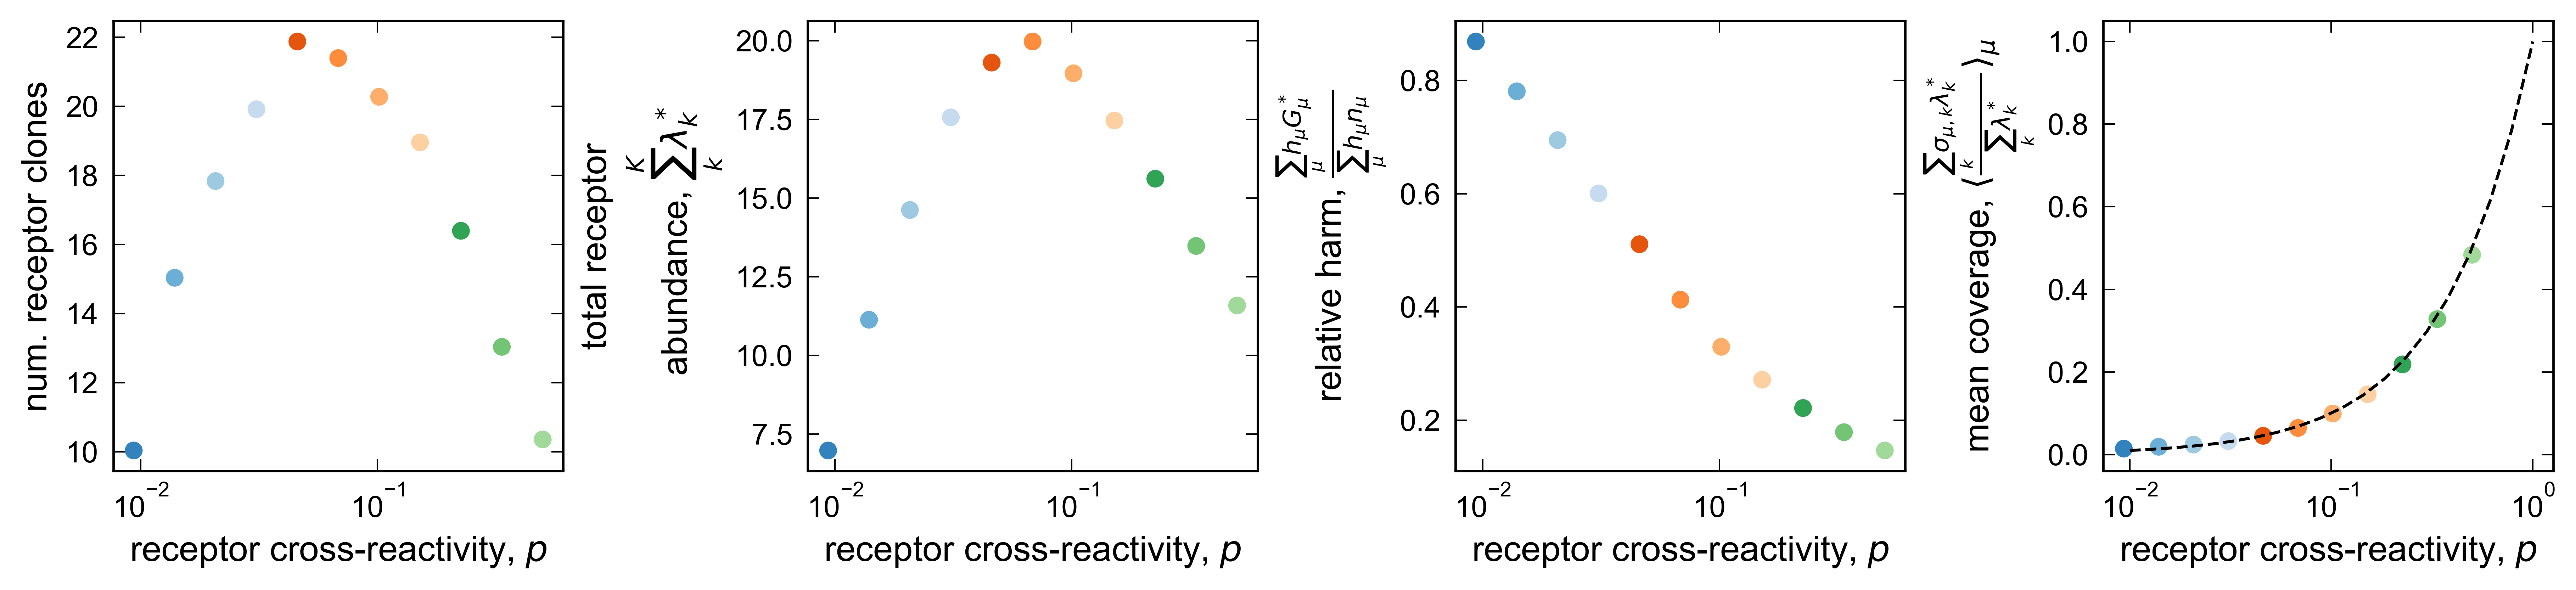

In [52]:
# Plot numerical values and analytic values verus beta
fig, axs = plt.subplots(1, 4, dpi = 300, figsize=(12, 3), layout='constrained')

axs[0].scatter(ps, rec_num_opts, color = [cmap(i) for i, c in enumerate(ps)])
# axs[0].plot([1.0,m], [1.0,m], 'k--')
axs[0].set(ylabel=r'num. receptor clones',xlabel=r'receptor cross-reactivity, $p$')

axs[1].scatter(ps, lam_opts, color = [cmap(i) for i, c in enumerate(ps)])
axs[1].set(ylabel='total receptor\n abundance, '+r'$\sum_k^K \lambda_k^*$', xlabel=r'receptor cross-reactivity, $p$')
# axs[1].semilogy()

axs[2].scatter(ps, (np.array(obj_opts) - 1/k*np.array(lam_opts))/np.sum(hCom1), color = [cmap(i) for i, c in enumerate(ps)])
axs[2].set(ylabel=r'relative harm, $\frac{\sum_\mu h_\mu G_\mu^*}{\sum_\mu h_\mu n_\mu}$', xlabel=r'receptor cross-reactivity, $p$')

axs[3].scatter(ps, [np.sum(u/(lam_opts[i] if lam_opts[i] > tol else 0))/m for i,u in enumerate(X_opts)], color = [cmap(i) for i, c in enumerate(ps)])
axs[3].set(ylabel=r'mean coverage, $\langle \frac{\sum_k\sigma_{\mu,k}\lambda_k^*}{\sum_k\lambda_k^*}\rangle_\mu$', xlabel=r'receptor cross-reactivity, $p$')
axs[3].plot(np.logspace(-2,0, 20), np.logspace(-2,0, 20), 'k--')

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.yaxis.set_tick_params(labelleft=True)
    ax.minorticks_off()
    ax.set_box_aspect(1)

fig.savefig('_figs/fig8_many_receptors_cross_reactivity'+'.png', dpi=300, bbox_inches='tight')

In [170]:
# # Initialize lists for storing results
# lam_opts = []
# obj_opts = []
# rec_num_opts = []
# X_opts = []
# avg_Sigmas = []
# runs = 10 # number of runs per cluster size

# for j in np.arange(1,int(2*m/3)):
#     obj_min, obj_minimizer, obj_rec_num, X, store_Sigmas = 0.0, 0.0, 0.0, 0.0, np.zeros((m,m))
#     for r in np.arange(0,runs):
#         # generate patterned matrix
#         cluster_sizes = np.ones(j, dtype = np.int32) + np.random.multinomial(m - j,np.ones(j)/j)
#         Sigma = np.zeros((m,m))
#         counter = 0
#         for c in cluster_sizes:
#             if c > 0:
#                 cluster_Sigma = np.random.uniform(low=0.0, high=1.0, size=(c,c))
#                 cluster_Sigma[:,0] = np.ones(c)*np.random.uniform(low=0.0, high=1.0)
#                 Sigma[counter:(counter + c), counter:(counter + c)] += cluster_Sigma
#                 counter += c

#         # Minimize harm
#         res_harm = minimize(objective, args = (beta, Sigma, np.ones(m), np.ones(m)),
#                  x0 = np.ones(m).tolist(),
#                  tol=1e-12,
#                  constraints = LinearConstraint(np.eye(m), 0.0, np.inf))
#         obj_min += res_harm.fun
#         obj_minimizer += res_harm.x
#         obj_rec_num += np.sum(res_harm.x > 1e-6)
#         X += Sigma.dot(res_harm.x)
#         store_Sigmas += Sigma
        
#     lam_opts.append(obj_minimizer/runs)
#     obj_opts.append(obj_min/runs)
#     rec_num_opts.append(obj_rec_num/runs)
#     X_opts.append(X/runs)
#     avg_Sigmas.append(store_Sigmas/runs)
#     # add average number of microbes bound by each receptor

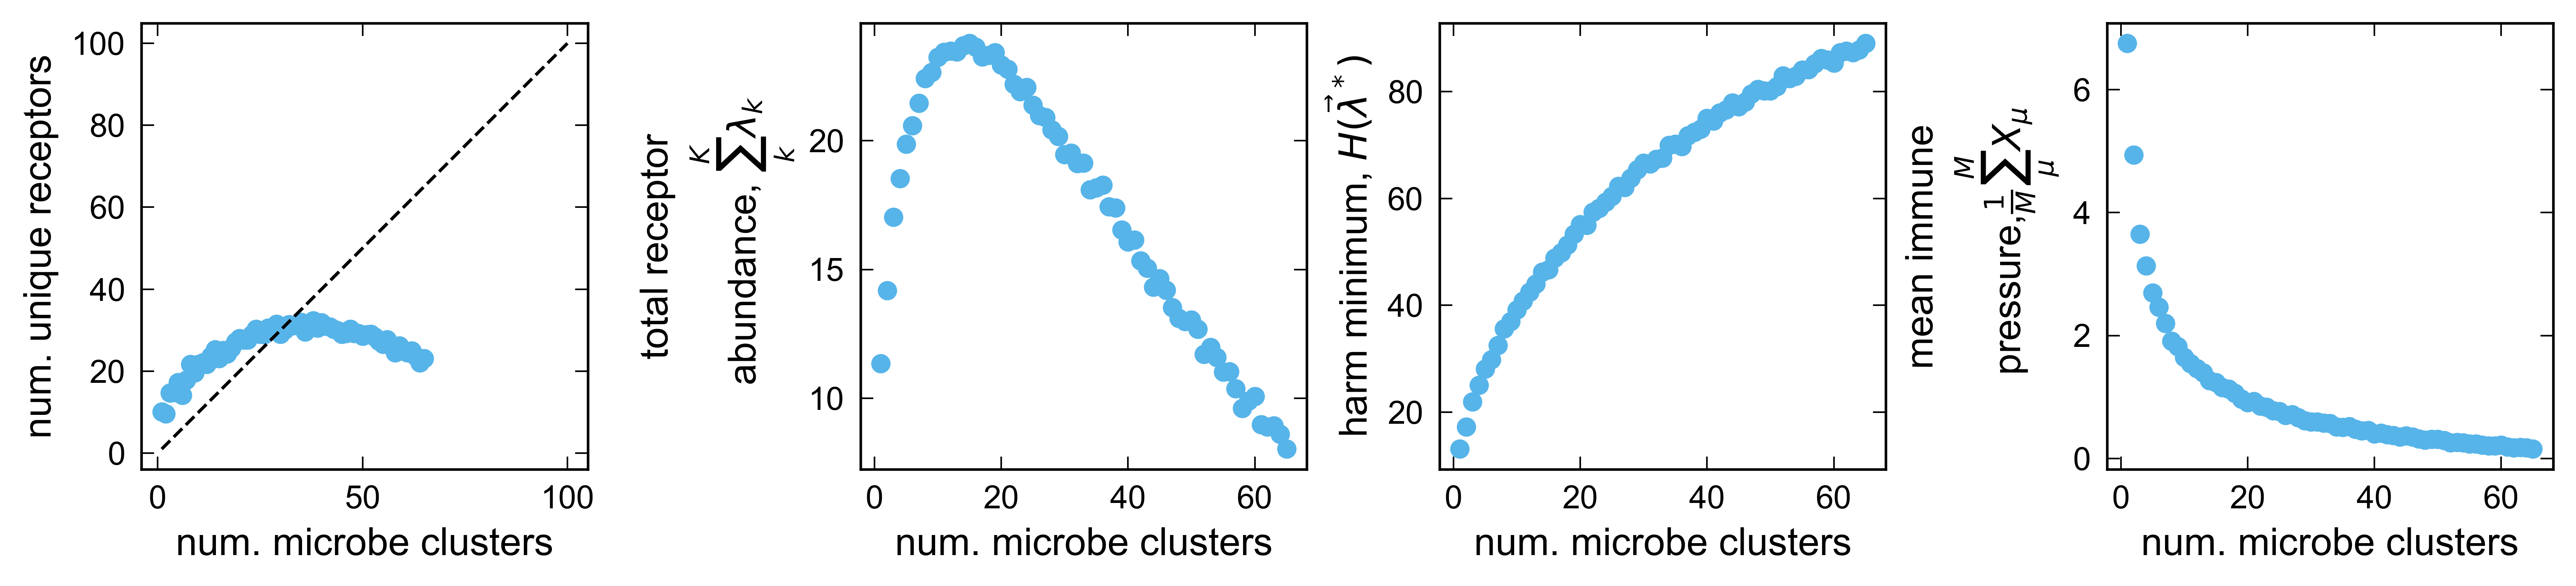

In [171]:
# # Plot numerical values and analytic values verus beta
# fig, axs = plt.subplots(1, 4, dpi = 300, figsize=(11, 3), layout='constrained')

# axs[0].scatter(np.arange(1, int(2*m/3)), rec_num_opts)
# axs[0].plot([1.0,m], [1.0,m], 'k--')
# axs[0].set(ylabel=r'num. unique receptors',xlabel=r'num. microbe clusters')

# axs[1].scatter(np.arange(1, int(2*m/3)), [np.sum(u) for u in lam_opts])
# axs[1].set(ylabel='total receptor\n abundance, '+r'$\sum_k^K \lambda_k$', xlabel=r'num. microbe clusters')

# axs[2].scatter(np.arange(1, int(2*m/3)), np.array(obj_opts) - beta*np.array([np.sum(u) for u in lam_opts]))
# axs[2].set(ylabel=r'harm minimum, $H(\vec\lambda^*)$', xlabel=r'num. microbe clusters')

# axs[3].scatter(np.arange(1, int(2*m/3)), [np.sum(u)/m for u in X_opts])
# axs[3].set(ylabel='mean immune\n pressure,'+ r'$\frac{1}{M}\sum_\mu^M X_\mu$', xlabel=r'num. microbe clusters')

# for j, ax in enumerate(axs.flat):
#     ax.xaxis.set_tick_params(labelbottom=True)
#     ax.yaxis.set_tick_params(labelleft=True)
#     ax.minorticks_off()
#     ax.set_box_aspect(1)

# fig.savefig('_figs/microbe_cluster_v_observables_beta_1'+'.png', dpi=300, bbox_inches='tight')